# Figuras y cálculos de referencia

In [93]:
import geopandas as gpd
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
%pip install pyarrow

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
Note: you may need to restart the kernel to use updated packages.


In [94]:
from pathlib import Path

DATOS = Path("..") / "datos"
REFERENCIAS = DATOS / "referencias"

### Traslados internos

In [95]:
datos_mx = pd.read_csv(DATOS / "procesados/datos_analizados_solomx.csv")

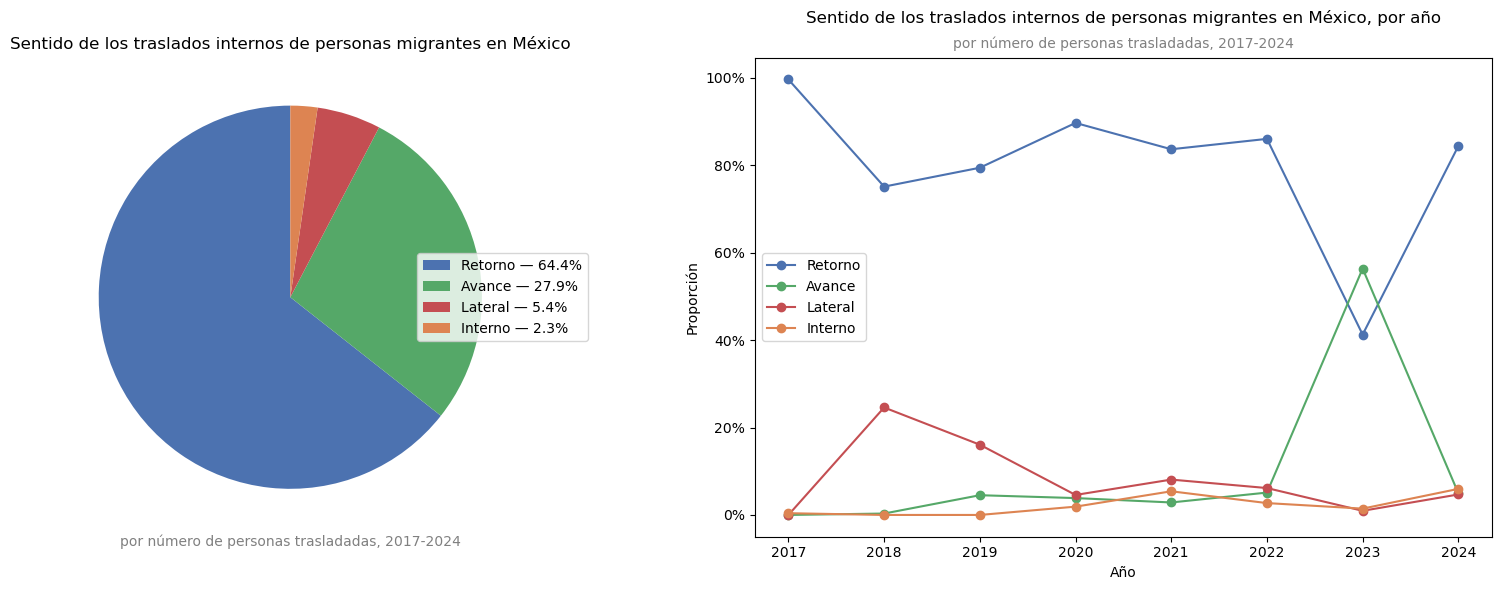

In [96]:
# Explorar sentido de los traslados por personas trasladadas 
label_map_sentido = {
    'ret': 'Retorno',
    'lat': 'Lateral',
    'ava': 'Avance',
    'int': 'Interno'
}

order_sentido = ['Retorno', 'Avance', 'Lateral', 'Interno']
colors = {
    'Retorno': '#4C72B0',
    'Avance':  '#55A868',
    'Lateral': '#C44E52',
    'Interno': '#DD8452'
}

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Pie Chart ---
sentido_sum = datos_mx.groupby('sentido')['total_migrantes_traslado'].sum()
sentido_sum.index = sentido_sum.index.map(label_map_sentido)
sentido_sum = sentido_sum.reindex(order_sentido).dropna()

wedges, _, autotexts = axes[0].pie(
    sentido_sum,
    labels=None,
    autopct='%1.1f%%',
    startangle=90,
    colors=[colors[c] for c in sentido_sum.index]
)

pct_labels = [f'{label} — {at.get_text()}' for label, at in zip(sentido_sum.index, autotexts)]
for at in autotexts:
    at.set_visible(False)

axes[0].legend(wedges, pct_labels, loc='center left', bbox_to_anchor=(0.75, 0.5))
axes[0].set_title('Sentido de los traslados internos de personas migrantes en México')
axes[0].text(0.5, -0.02, 'por número de personas trasladadas, 2017-2024', transform=axes[0].transAxes,
             ha='center', fontsize=10, color='gray')


# --- Line Chart ---
sentido_year = datos_mx.groupby(['year', 'sentido'])['total_migrantes_traslado'].sum().unstack(fill_value=0)
sentido_year_pct = sentido_year.div(sentido_year.sum(axis=1), axis=0)
sentido_year_pct.columns = sentido_year_pct.columns.map(label_map_sentido)
sentido_year_pct = sentido_year_pct.reindex(columns=order_sentido)

for col in sentido_year_pct.columns:
    axes[1].plot(sentido_year_pct.index, sentido_year_pct[col], marker='o', label=col, color=colors[col])

axes[1].set_xticks(datos_mx['year'].unique())
axes[1].set_xlabel('Año')
axes[1].set_ylabel('Proporción')
axes[1].set_title('Sentido de los traslados internos de personas migrantes en México, por año', pad=25)
axes[1].text(0.5, 1.02, 'por número de personas trasladadas, 2017-2024', transform=axes[1].transAxes,
             ha='center', fontsize=10, color='gray')
axes[1].legend()
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

plt.tight_layout()

plt.show()

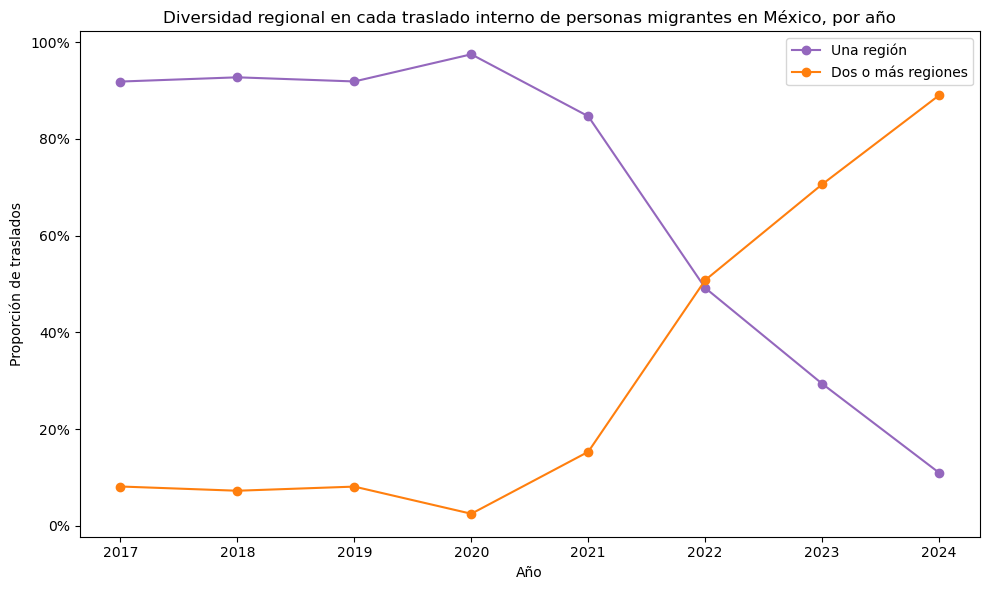

In [97]:
# Explorar la diversidad regional de los traslados
order_div = ['Una región', 'Dos o más regiones']
colors = {
    'Una región':          '#9467BD',
    'Dos o más regiones':        '#FF7F0E'
}

diversity_year = datos_mx.groupby(['year', 'diversity_cat']).size().unstack(fill_value=0)
diversity_year = diversity_year.reindex(columns=order_div)
diversity_year_pct = diversity_year.div(diversity_year.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(10, 6))

for col in order_div:
    ax.plot(diversity_year_pct.index, diversity_year_pct[col], marker='o', label=col, color=colors[col])

ax.set_xticks(datos_mx['year'].unique())
ax.set_xlabel('Año')
ax.set_ylabel('Proporción de traslados')
ax.set_title('Diversidad regional en cada traslado interno de personas migrantes en México, por año')
ax.legend()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

plt.tight_layout()

plt.show()

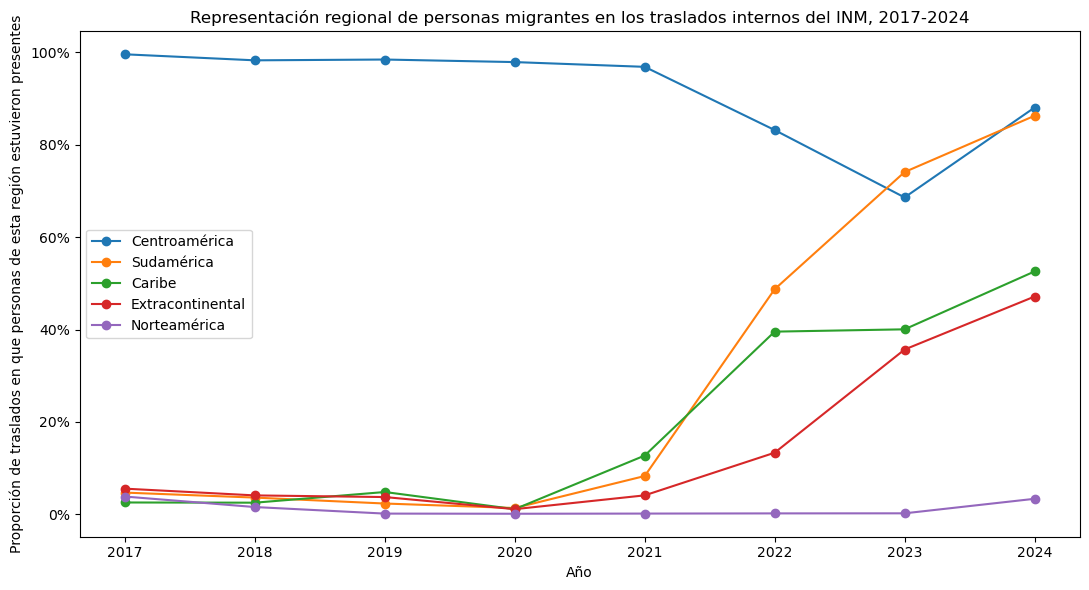

In [98]:
# Explorar regiones de origen de migrantes en cada traslado 
region_cols = ['centroamerica', 'sudamerica', 'caribe', 'extracontinentales', 'norteamerica']
label_map_region = {
    'centroamerica':      'Centroamérica',
    'sudamerica':         'Sudamérica',
    'caribe':             'Caribe',
    'extracontinentales': 'Extracontinental',
    'norteamerica':       'Norteamérica',
}

region_year = datos_mx.groupby('year')[region_cols].mean()
region_year.columns = region_year.columns.map(label_map_region)

fig, ax = plt.subplots(figsize=(11, 6))

for col in region_year.columns:
    ax.plot(region_year.index, region_year[col], marker='o', label=col)

ax.set_xticks(datos_mx['year'].unique())
ax.set_xlabel('Año')
ax.set_ylabel('Proporción de traslados en que personas de esta región estuvieron presentes')
ax.set_title('Representación regional de personas migrantes en los traslados internos del INM, 2017-2024')
ax.legend()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))

plt.tight_layout()
plt.show()

In [99]:
print(datos_mx['sentido'].value_counts(normalize=True) * 100)

sentido
ret    82.070450
ava     8.698607
lat     7.701891
int     1.529052
Name: proportion, dtype: float64


In [100]:
print(datos_mx['ems'].value_counts())

ems
ambos    5811
em_d     2117
em_o      646
no_em     255
Name: count, dtype: int64


In [101]:
datos_mx['ems'].value_counts(normalize=True) * 100

ems
ambos    65.817193
em_d     23.977800
em_o      7.316797
no_em     2.888209
Name: proportion, dtype: float64

In [102]:
ems_pct = datos_mx['ems'].value_counts(normalize=True) * 100

# Interpretar
bin_map_ems = {
    'ambos': 'to_em',
    'em_d': 'to_em',
    'em_o': 'no_em_d',
    'no_em': 'no_em_d'
}

binned_pct = ems_pct.rename(index=bin_map_ems).groupby(level=0).sum()
print(binned_pct)

ems
no_em_d    10.205006
to_em      89.794994
Name: proportion, dtype: float64


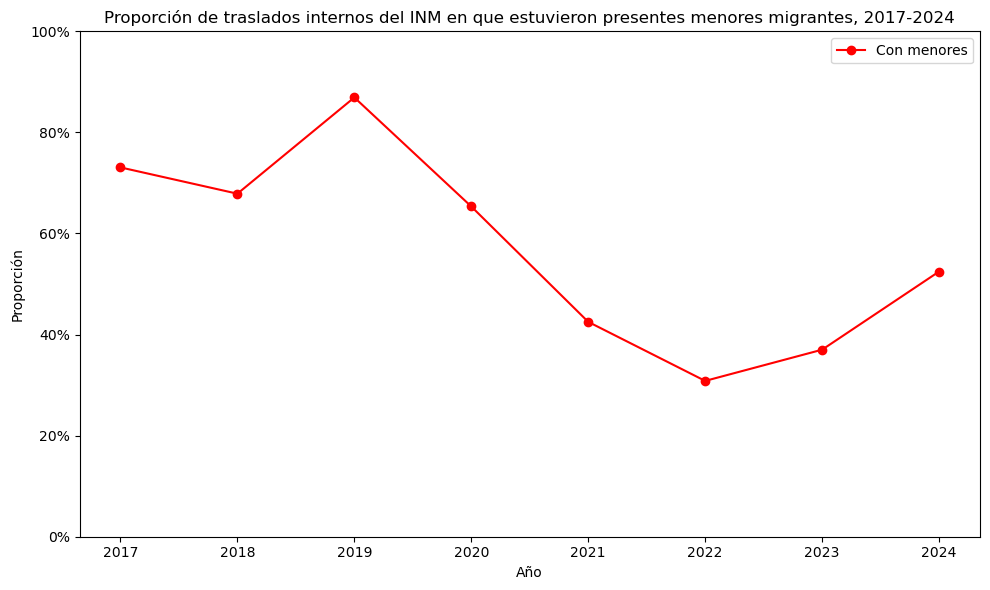

In [103]:
# Explorar tendencias de presencia de menores
menores_year = datos_mx.groupby('year')['menores_bin'].mean()

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(menores_year.index, menores_year, marker='o', color='red', label='Con menores')

ax.set_xticks(datos_mx['year'].unique())
ax.set_xlabel('Año')
ax.set_ylabel('Proporción')
ax.set_title('Proporción de traslados internos del INM en que estuvieron presentes menores migrantes, 2017-2024')
ax.legend()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_ylim(0, 1)
plt.tight_layout()

plt.show()

/var/folders/ct/w1dnv1_96gv76pztht3z9vgw0000gn/T/ipykernel_14126/1619677202.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


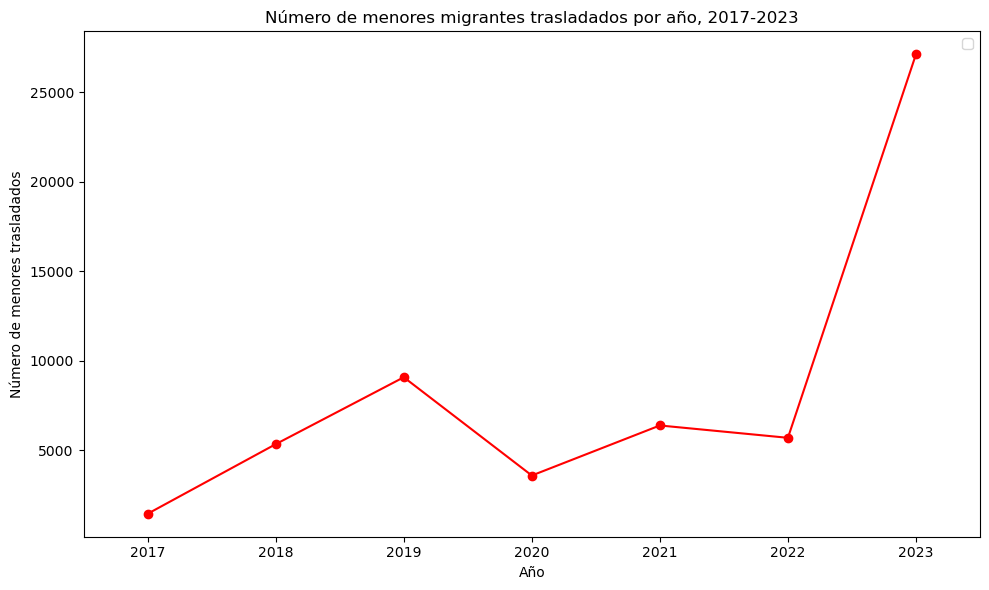

In [104]:
menores_sum = datos_mx[datos_mx['year'] <= 2023].groupby('year')['menores_num'].sum()

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(menores_sum.index, menores_sum, marker='o', color='red')

ax.set_xticks(datos_mx['year'].unique())
ax.set_xlim(2016.5, 2023.5)
ax.set_xlabel('Año')
ax.set_ylabel('Número de menores trasladados')
ax.set_title('Número de menores migrantes trasladados por año, 2017-2023')
ax.legend()

plt.tight_layout()

plt.show()

In [105]:
# Chequé a ver si hubo alguna tendencia muy diferente en el sentido de traslados de menores vs. adultos pero no vi una. 
datos_mx[datos_mx['menores_bin'] == 1]['sentido'].value_counts(normalize=True) * 100

sentido
ret    77.346891
lat    11.255616
ava     9.907780
int     1.489714
Name: proportion, dtype: float64

In [106]:
top5_destinos_overall_mun = (
    datos_mx
    .groupby(['year', 'destino_limpio_mun', 'destino_limpio_ent'])
    .size()
    .reset_index(name='count')
    .sort_values(['year', 'count'], ascending=[True, False])
    .groupby('year')
    .head(5)
    [['destino_limpio_mun', 'destino_limpio_ent', 'year']]
    .reset_index(drop=True)
)

top5_destinos_overall_mun = (
    top5_destinos_overall_mun
    .groupby(['destino_limpio_mun', 'destino_limpio_ent'])['year']
    .apply(lambda x: ', '.join(str(y) for y in sorted(x)))
    .reset_index()
)

top5_destinos_overall_mun = top5_destinos_overall_mun[top5_destinos_overall_mun['year'].str.contains(',')]

print(top5_destinos_overall_mun)

   destino_limpio_mun               destino_limpio_ent  \
0            Acayucan  Veracruz de Ignacio de la Llave   
1              Centro                          Tabasco   
4          Iztapalapa                 Ciudad de México   
12            Tampico                       Tamaulipas   
13          Tapachula                          Chiapas   

                                              year  
0         2017, 2018, 2019, 2020, 2021, 2022, 2023  
1                     2020, 2021, 2022, 2023, 2024  
4               2017, 2018, 2019, 2020, 2021, 2022  
12                                2018, 2020, 2021  
13  2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024  


In [107]:
top5_origenes_overall_mun = (
    datos_mx
    .groupby(['year', 'origen_limpio_mun', 'origen_limpio_ent'])
    .size()
    .reset_index(name='count')
    .sort_values(['year', 'count'], ascending=[True, False])
    .groupby('year')
    .head(5)
    [['origen_limpio_mun', 'origen_limpio_ent', 'year']]
    .reset_index(drop=True)
)

top5_origenes_overall_mun = (
    top5_origenes_overall_mun
    .groupby(['origen_limpio_mun', 'origen_limpio_ent'])['year']
    .apply(lambda x: ', '.join(str(y) for y in sorted(x)))
    .reset_index()
)

top5_origenes_overall_mun = top5_origenes_overall_mun[top5_origenes_overall_mun['year'].str.contains(',')]

print(top5_origenes_overall_mun)

   origen_limpio_mun                origen_limpio_ent  \
0           Acayucan  Veracruz de Ignacio de la Llave   
4         Hermosillo                           Sonora   
7       Nuevo Laredo                       Tamaulipas   
8     Piedras Negras             Coahuila de Zaragoza   
9             Puebla                           Puebla   
10           Reynosa                       Tamaulipas   
11   San Luis Potosí                  San Luis Potosí   
13           Tampico                       Tamaulipas   
14         Tenosique                          Tabasco   

                                        year  
0                           2020, 2022, 2024  
4                           2022, 2023, 2024  
7                     2017, 2018, 2019, 2020  
8   2018, 2019, 2020, 2021, 2022, 2023, 2024  
9                                 2021, 2024  
10        2018, 2019, 2020, 2021, 2022, 2023  
11                          2017, 2018, 2019  
13                                2020, 2021  
14    

/var/folders/ct/w1dnv1_96gv76pztht3z9vgw0000gn/T/ipykernel_14126/1260347550.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


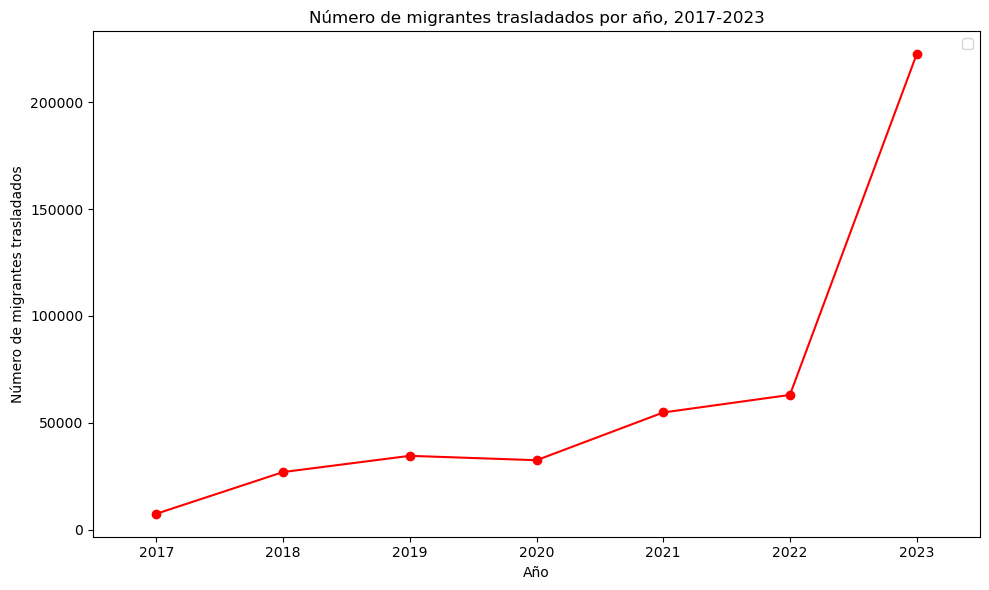

In [108]:
personas_sum = datos_mx[datos_mx['year'] <= 2023].groupby('year')['total_migrantes_traslado'].sum()

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(personas_sum.index, personas_sum, marker='o', color='red')

ax.set_xticks(datos_mx['year'].unique())
ax.set_xlim(2016.5, 2023.5)
ax.set_xlabel('Año')
ax.set_ylabel('Número de migrantes trasladados')
ax.set_title('Número de migrantes trasladados por año, 2017-2023')
ax.legend()

plt.tight_layout()
plt.show()

In [109]:
print(datos_mx['correspondencia'].value_counts(normalize=True) * 100)

correspondencia
ruta_cont_1         44.365160
ruta_cont_2         24.340242
rutas_diferentes    12.787405
o_fuera             12.379658
d_fuera              5.957640
ambos_fuera          0.169895
Name: proportion, dtype: float64


In [110]:
em = pd.read_csv(REFERENCIAS / "EMs.csv")

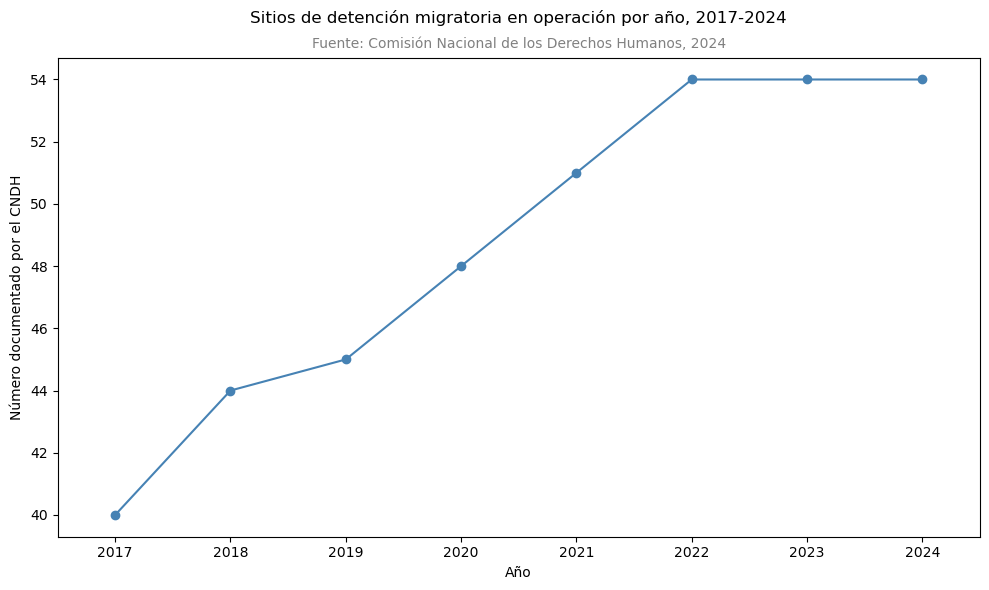

In [111]:
years = list(range(2017, 2025))
ems_active = []

for year in years:
    count = (em['operaciones_desde'] <= year).sum()
    ems_active.append(count)

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(years, ems_active, marker='o', color='steelblue')

ax.set_xticks(years)
ax.set_xlabel('Año')
ax.set_ylabel('Número documentado por el CNDH')
ax.set_title('Sitios de detención migratoria en operación por año, 2017-2024', pad=25)
ax.text(0.5, 1.02, 'Fuente: Comisión Nacional de los Derechos Humanos, 2024', transform=ax.transAxes,
             ha='center', fontsize=10, color='gray')
ax.set_xlim(2016.5, 2024.5)

plt.tight_layout()

plt.show()

In [112]:
mun_lookup = datos_mx[['origen_cve', 'origen_limpio_mun', 'destino_cve', 'destino_limpio_mun']].drop_duplicates()
top5_rutas_pormigrantes = (
    datos_mx.groupby(['origen_cve', 'destino_cve'], as_index=False)['total_migrantes_traslado']
      .sum()
      .sort_values('total_migrantes_traslado', ascending=False)
      .head(5)
)

top5_rutas_pormigrantes = top5_rutas_pormigrantes.merge(mun_lookup, on=['origen_cve', 'destino_cve'], how='left')
print(top5_rutas_pormigrantes)

   origen_cve  destino_cve  total_migrantes_traslado origen_limpio_mun  \
0        7089         7101                     59762         Tapachula   
1        7087         7101                     33726          Suchiate   
2       28032        27004                     19835           Reynosa   
3        7101         7089                     16954  Tuxtla Gutiérrez   
4        5025        27004                     15281    Piedras Negras   

  destino_limpio_mun  
0   Tuxtla Gutiérrez  
1   Tuxtla Gutiérrez  
2             Centro  
3          Tapachula  
4             Centro  


In [113]:
print(datos_mx['total_migrantes_traslado'].sum())

483190


In [114]:
print(datos_mx.loc[datos_mx['year'] == 2023, 'total_migrantes_traslado'].sum())

222338


In [115]:
print(datos_mx.loc[datos_mx['year'] == 2017, 'total_migrantes_traslado'].sum())

7516


In [116]:
# 2023 vs. 2017 número de personas trasladadas
222338/7516

29.581958488557742

In [117]:
# Qué proporción del total tiene 2023
222338/483190*100

46.01461122953703

In [118]:
print(datos_mx['menores_num'].sum())

64763


In [119]:
# Último año en que fue legal alojar a menores de edad en estaciones / estancias del INM
print(datos_mx.loc[datos_mx['year'] == 2020, 'menores_num'].sum())

3575


In [120]:
# Después de la prohibición
print(datos_mx.loc[datos_mx['year'] == 2023, 'menores_num'].sum())

27126


In [121]:
# 2023 vs 2020
27126/3575

7.587692307692308

### Las deportaciones

In [128]:
datos_menores_regiones = pd.read_csv(DATOS / "procesados/datos_analizados_condep.csv")

In [129]:
print(datos_menores_regiones['sentido'].value_counts())

sentido
ret    7246
dep    2057
ava     768
lat     680
int     135
Name: count, dtype: int64


In [130]:
# Deportaciones como proporción del total
2057/(7246+2057+768+680+135)

0.18895829505787248

In [131]:
# Cuántas personas fueron deportadas
print(datos_menores_regiones.loc[datos_menores_regiones['sentido'] == 'dep', 'total_migrantes_traslado'].sum())

99332


In [132]:
# Cuántos menores
print(datos_menores_regiones.loc[datos_menores_regiones['sentido'] == 'dep', 'menores_num'].sum())

11628


In [133]:
datos_dep = datos_menores_regiones[datos_menores_regiones['sentido'] == 'dep']

In [134]:
region_cols_dep = ['centroamerica', 'norteamerica', 'caribe', 'sudamerica', 'extracontinentales']
print(datos_dep[region_cols_dep].sum())

centroamerica         2054
norteamerica             2
caribe                  19
sudamerica              23
extracontinentales      26
dtype: int64


In [135]:
# A dónde deportaron a personas norteamericanas
print(datos_dep.loc[datos_dep['norteamerica'] == 1, 'lugar_destino'])

8361     Estados Unidos
10601    Estados Unidos
Name: lugar_destino, dtype: object


In [136]:
# A dónde deportaron a personas sudamericanas
print(datos_dep.loc[datos_dep['sudamerica'] == 1, 'lugar_destino'])

96         Guatemala
4201       Guatemala
4205       Guatemala
4206       Guatemala
4868        Honduras
5724     El Salvador
5766       Guatemala
7914       Guatemala
7915       Guatemala
7918       Guatemala
7919       Guatemala
7920       Guatemala
7923       Guatemala
7955       Guatemala
7956       Guatemala
7964       Guatemala
7968       Guatemala
7969       Guatemala
7979       Guatemala
7991       Guatemala
7996       Guatemala
10298      Guatemala
10573      Guatemala
Name: lugar_destino, dtype: object


In [137]:
# A dónde deportaron a personas caribeñas
print(datos_dep.loc[datos_dep['caribe'] == 1, 'lugar_destino'])

4184      Guatemala
4192      Guatemala
4201      Guatemala
4207      Guatemala
4867       Honduras
4868       Honduras
5033      Guatemala
5724    El Salvador
7914      Guatemala
7915      Guatemala
7918      Guatemala
7919      Guatemala
7923      Guatemala
7954      Guatemala
7955      Guatemala
7956      Guatemala
7964      Guatemala
7968      Guatemala
7996      Guatemala
Name: lugar_destino, dtype: object


In [138]:
# A dónde deportaron a personas extracontinentales
print(datos_dep.loc[datos_dep['extracontinentales'] == 1, 'lugar_destino'])

2327        El Salvador
4206          Guatemala
7915          Guatemala
7919          Guatemala
7954          Guatemala
7955          Guatemala
7956          Guatemala
7968          Guatemala
7969          Guatemala
7979          Guatemala
7991          Guatemala
7996          Guatemala
8361     Estados Unidos
9004           Honduras
9005           Honduras
9007           Honduras
9008           Honduras
9010           Honduras
9011           Honduras
9012           Honduras
9014           Honduras
9015           Honduras
9019           Honduras
9022           Honduras
9023           Honduras
10573         Guatemala
Name: lugar_destino, dtype: object


In [139]:
# A dónde deportaron a personas centroamericanas
print(datos_dep.loc[datos_dep['centroamerica'] == 1, 'lugar_destino'].value_counts())

lugar_destino
Honduras       1039
Guatemala       990
El Salvador      21
Deportación       2
Belice            1
Nicaragua         1
Name: count, dtype: int64


/var/folders/ct/w1dnv1_96gv76pztht3z9vgw0000gn/T/ipykernel_14126/931680891.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


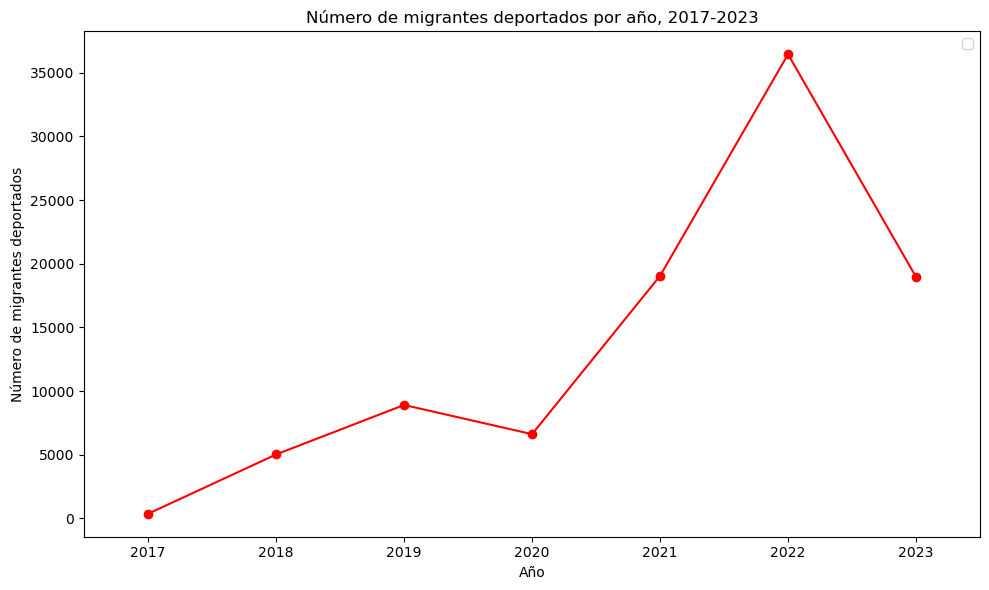

In [140]:
# Tendencias en las deportaciones registradas en la base de traslados internos
dep_sum = datos_dep[datos_dep['year'] <= 2023].groupby('year')['total_migrantes_traslado'].sum()

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(dep_sum.index, dep_sum, marker='o', color='red')

ax.set_xticks(datos_dep['year'].unique())
ax.set_xlim(2016.5, 2023.5)
ax.set_xlabel('Año')
ax.set_ylabel('Número de migrantes deportados')
ax.set_title('Número de migrantes deportados por año, 2017-2023')
ax.legend()

plt.tight_layout()
plt.show()

/var/folders/ct/w1dnv1_96gv76pztht3z9vgw0000gn/T/ipykernel_14126/216643552.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


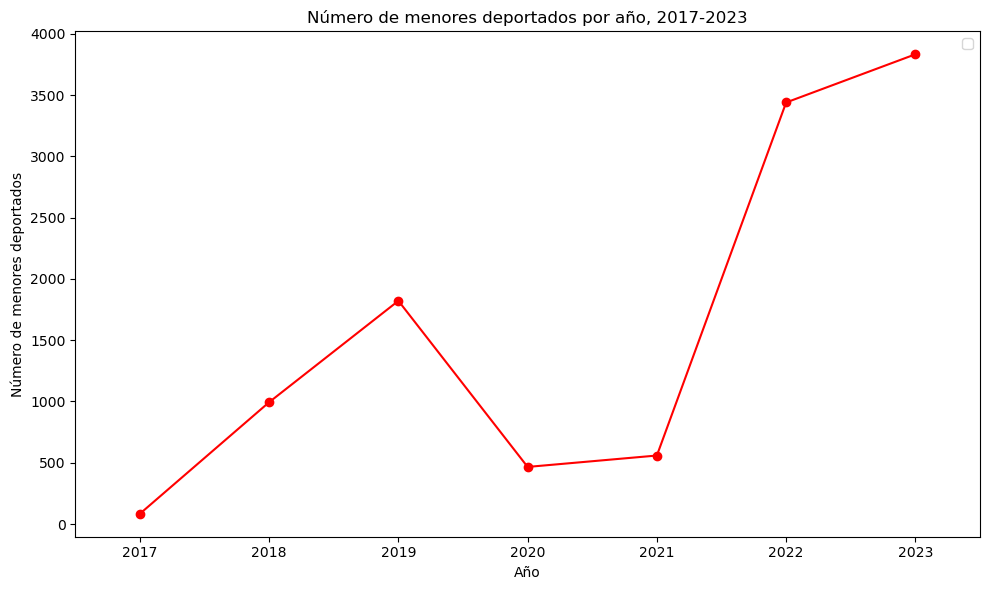

In [141]:
# Tendencias en la presencia de menores en las deportaciones registradas en la base de traslados internos
dep_men_sum = datos_dep[datos_dep['year'] <= 2023].groupby('year')['menores_num'].sum()

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(dep_men_sum.index, dep_men_sum, marker='o', color='red')

ax.set_xticks(datos_dep['year'].unique())
ax.set_xlim(2016.5, 2023.5)
ax.set_xlabel('Año')
ax.set_ylabel('Número de menores deportados')
ax.set_title('Número de menores deportados por año, 2017-2023')
ax.legend()

plt.tight_layout()
plt.show()

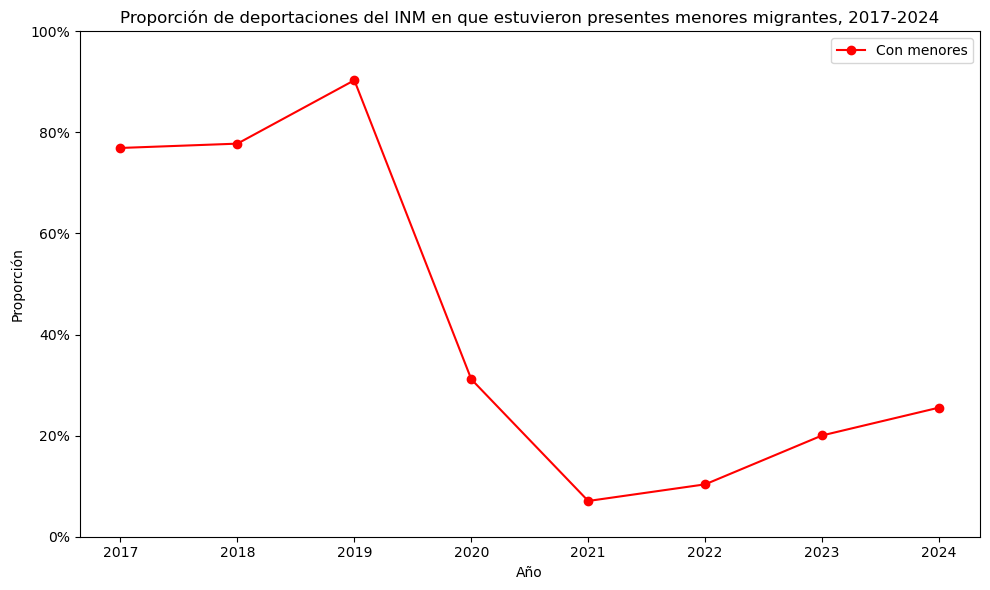

In [142]:
# Tendencias en la presencia de menores en las deportaciones registradas en la base de traslados internos
men_dep_year = datos_dep.groupby('year')['menores_bin'].mean()

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(men_dep_year.index, men_dep_year, marker='o', color='red', label='Con menores')

ax.set_xticks(datos_dep['year'].unique())
ax.set_xlabel('Año')
ax.set_ylabel('Proporción')
ax.set_title('Proporción de deportaciones del INM en que estuvieron presentes menores migrantes, 2017-2024')
ax.legend()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

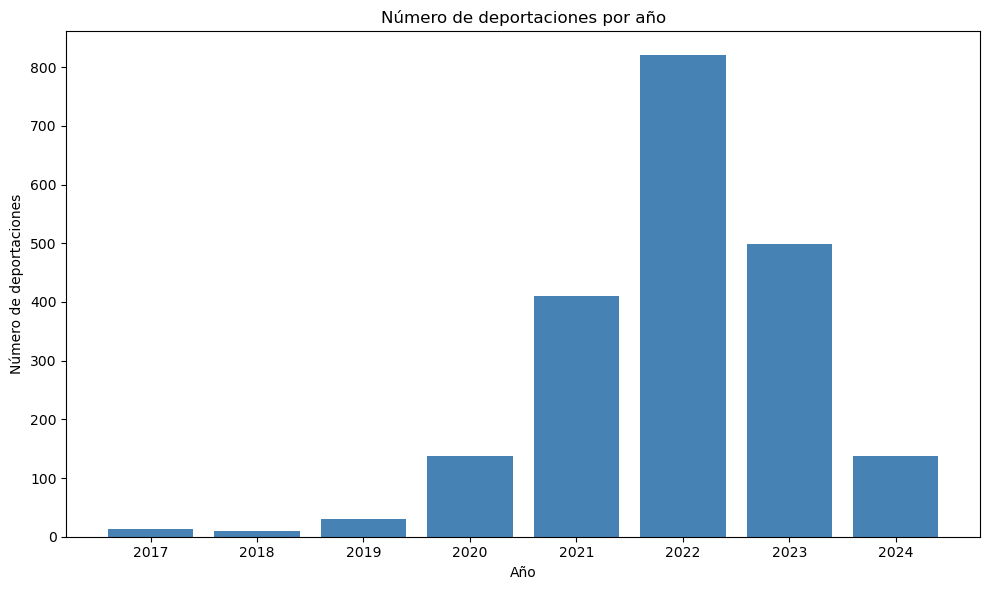

In [143]:
year_counts = datos_dep['year'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(year_counts.index, year_counts.values, color='steelblue')
ax.set_xlabel('Año')
ax.set_ylabel('Número de deportaciones')
ax.set_title('Número de deportaciones por año')
ax.set_xticks(year_counts.index)
plt.tight_layout()
plt.show()

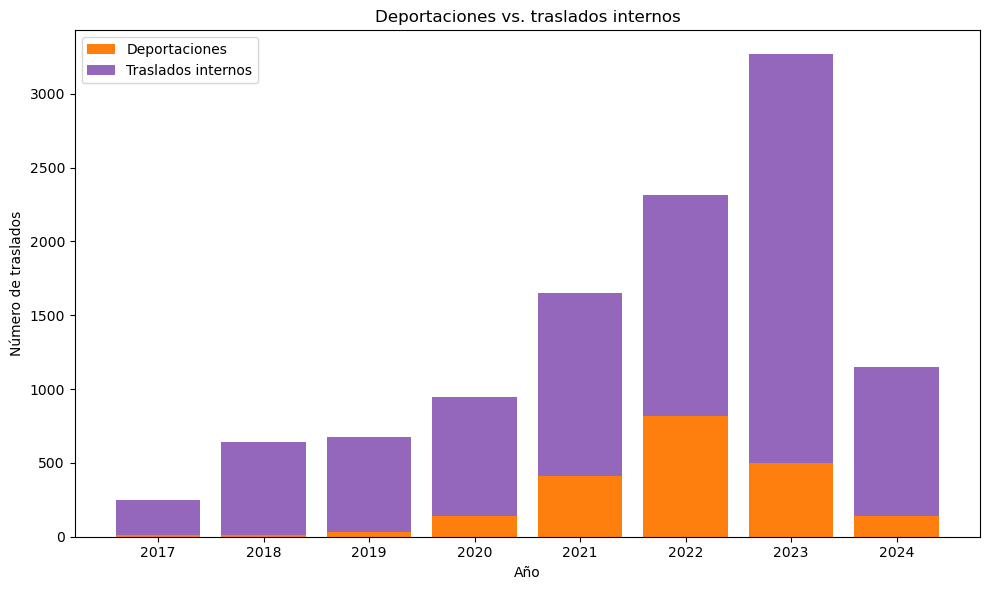

In [144]:
dep_counts = datos_menores_regiones[datos_menores_regiones['sentido'] == 'dep'].groupby('year').size()
otro_counts = datos_menores_regiones[datos_menores_regiones['sentido'] != 'dep'].groupby('year').size()

years = sorted(datos_menores_regiones['year'].unique())
dep_counts = dep_counts.reindex(years, fill_value=0)
otro_counts = otro_counts.reindex(years, fill_value=0)

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(years, dep_counts, label='Deportaciones', color='#FF7F0E')
ax.bar(years, otro_counts, bottom=dep_counts, label='Traslados internos', color='#9467BD')

ax.set_xlabel('Año')
ax.set_ylabel('Número de traslados')
ax.set_title('Deportaciones vs. traslados internos')
ax.set_xticks(years)
ax.legend()
plt.tight_layout()

plt.show()

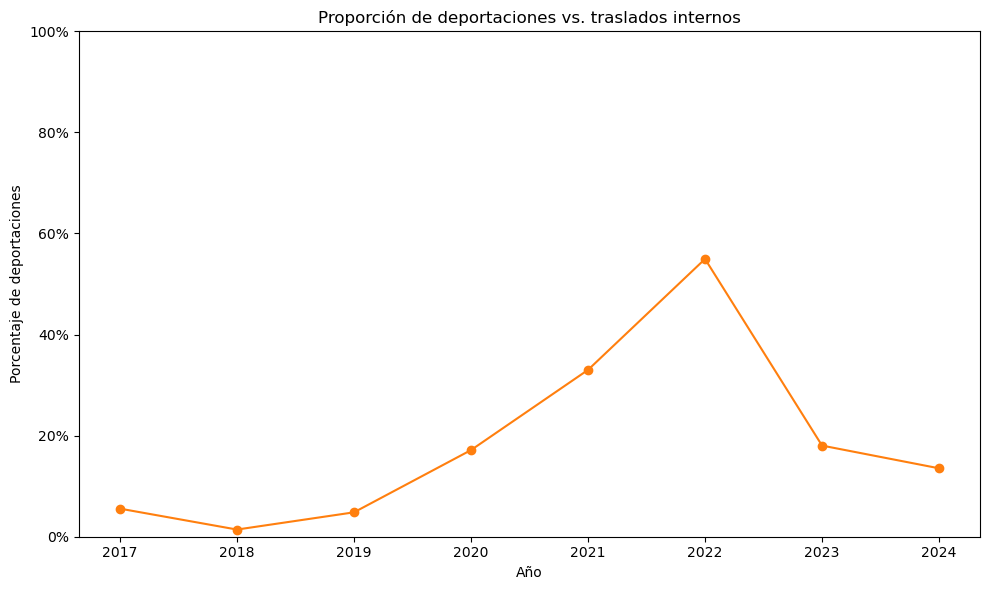

In [145]:
dep_counts = datos_menores_regiones[datos_menores_regiones['sentido'] == 'dep'].groupby('year').size()
otro_counts = datos_menores_regiones[datos_menores_regiones['sentido'] != 'dep'].groupby('year').size()

years = sorted(datos_menores_regiones['year'].unique())
dep_counts = dep_counts.reindex(years, fill_value=0)
otro_counts = otro_counts.reindex(years, fill_value=0)

ratio = dep_counts / otro_counts

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(years, ratio, marker='o', color='#FF7F0E')

ax.set_xlabel('Año')
ax.set_ylabel('Porcentaje de deportaciones')
ax.set_title('Proporción de deportaciones vs. traslados internos')
ax.set_xticks(years)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
plt.tight_layout()
plt.show()

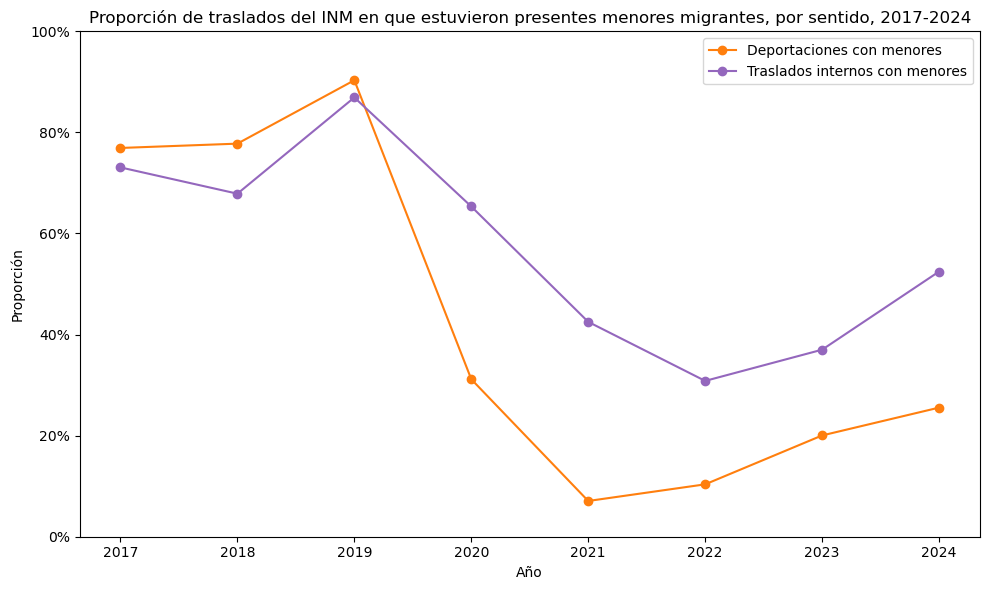

In [146]:
dep_df = datos_menores_regiones[datos_menores_regiones['sentido'] == 'dep']
otro_df = datos_menores_regiones[datos_menores_regiones['sentido'] != 'dep']

men_dep_year = dep_df.groupby('year')['menores_bin'].mean()
men_otro_year = otro_df.groupby('year')['menores_bin'].mean()

years = sorted(datos_menores_regiones['year'].unique())
men_dep_year = men_dep_year.reindex(years)
men_otro_year = men_otro_year.reindex(years)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(years, men_dep_year, marker='o', color='#FF7F0E', label='Deportaciones con menores')
ax.plot(years, men_otro_year, marker='o', color='#9467BD', label='Traslados internos con menores')
ax.set_xticks(years)
ax.set_xlabel('Año')
ax.set_ylabel('Proporción')
ax.set_title('Proporción de traslados del INM en que estuvieron presentes menores migrantes, por sentido, 2017-2024')
ax.legend()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}'))
ax.set_ylim(0, 1)
plt.tight_layout()

plt.show()

In [147]:
datos_dep.to_csv(DATOS / "procesados" / "datos_analizados_solodep.csv", index=False)

# Cálculos para visualizaciones en Flourish

In [148]:
print(len(datos_mx))

8829


In [149]:
print(len(datos_menores_regiones))

10886


In [150]:
print(
    datos_mx.loc[
        datos_mx['destino_limpio_mun'] == 'Tuxtla Gutiérrez',
        'year'
    ].value_counts().sort_index()
)

year
2019      2
2020     11
2021     12
2022     14
2023    382
2024     16
Name: count, dtype: int64


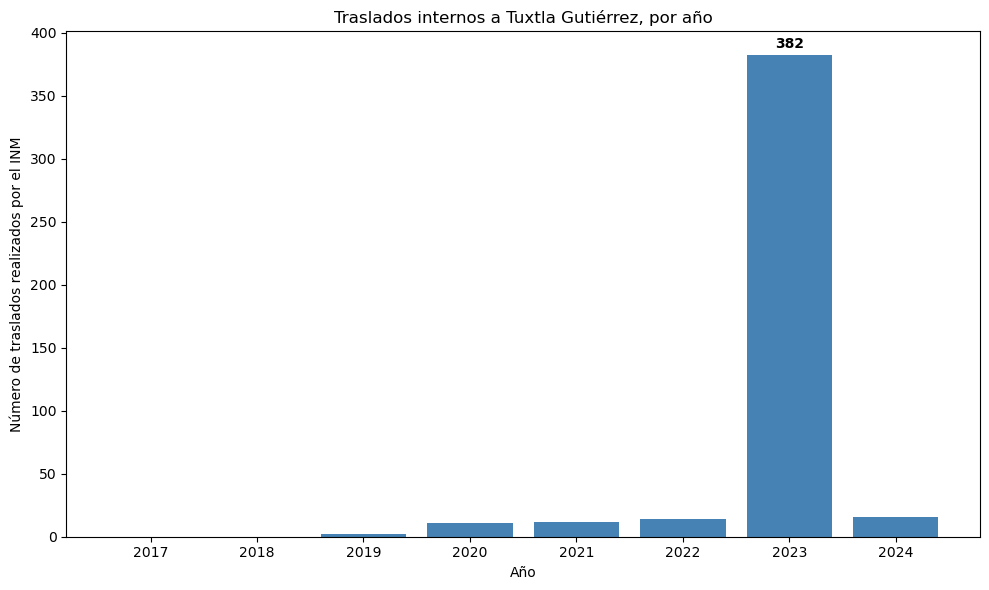

In [151]:
tuxtla_year = (
    datos_mx.loc[
        datos_mx['destino_limpio_mun'] == 'Tuxtla Gutiérrez',
        'year'
    ].value_counts().sort_index()
)

years = sorted(datos_mx['year'].unique())
tuxtla_year = tuxtla_year.reindex(years, fill_value=0)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(tuxtla_year.index, tuxtla_year.values, color='steelblue')

max_year = tuxtla_year.idxmax()
max_val = tuxtla_year.max()
ax.annotate(
    f'{max_val:,}',
    xy=(max_year, max_val),
    xytext=(0, 5),
    textcoords='offset points',
    ha='center',
    fontweight='bold'
)

ax.set_xlabel('Año')
ax.set_ylabel('Número de traslados realizados por el INM')
ax.set_title('Traslados internos a Tuxtla Gutiérrez, por año')
ax.set_xticks(years)
plt.tight_layout()
plt.show()

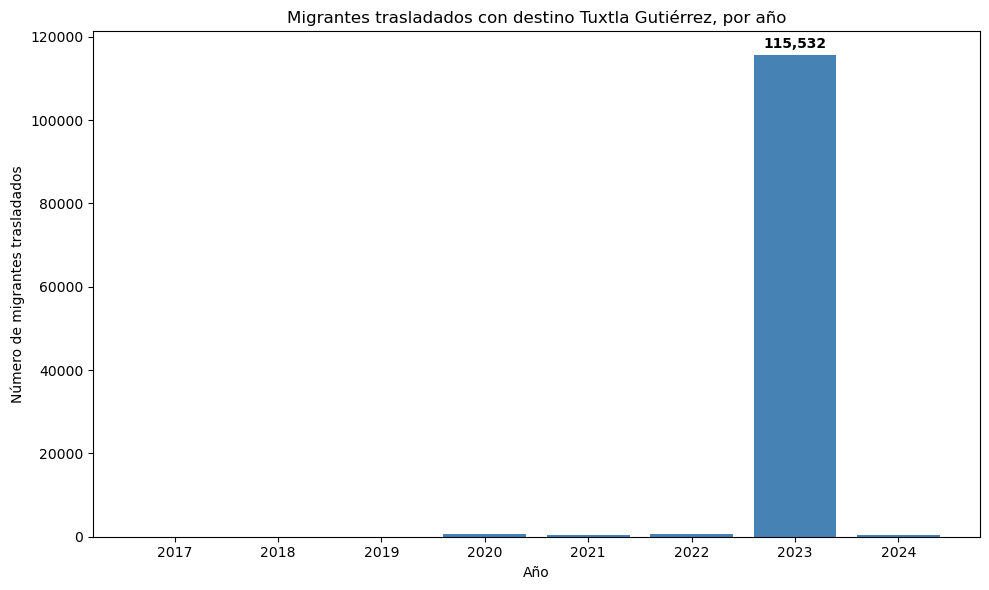

In [152]:
tuxtla_sum_year = (
    datos_mx.loc[
        datos_mx['destino_limpio_mun'] == 'Tuxtla Gutiérrez'
    ].groupby('year')['total_migrantes_traslado'].sum()
)

years = sorted(datos_mx['year'].unique())
tuxtla_sum_year = tuxtla_sum_year.reindex(years, fill_value=0)

fig, ax = plt.subplots(figsize=(10, 6))
ax.bar(tuxtla_sum_year.index, tuxtla_sum_year.values, color='steelblue')

max_year = tuxtla_sum_year.idxmax()
max_val = tuxtla_sum_year.max()
ax.annotate(
    f'{max_val:,.0f}',
    xy=(max_year, max_val),
    xytext=(0, 5),
    textcoords='offset points',
    ha='center',
    fontweight='bold'
)

ax.set_xlabel('Año')
ax.set_ylabel('Número de migrantes trasladados')
ax.set_title('Migrantes trasladados con destino Tuxtla Gutiérrez, por año')
ax.set_xticks(years)
plt.tight_layout()
plt.show()

In [153]:
# Archivo para graficar correspondencia
corr_year = (
    datos_mx.groupby(['year', 'correspondencia_bin'])['total_migrantes_traslado']
    .sum()
    .unstack('correspondencia_bin')
    .reset_index()
)

corr_year['year'] = corr_year['year'].astype(int).astype(str)

PARA_FIGURAS = Path("..") / "para_figuras"
corr_year.to_csv(PARA_FIGURAS / "corr_year.csv", index=False)

In [154]:
# Archivo para graficar caso de Tuxtla
tuxtla_sum_year = (
    datos_mx.loc[
        datos_mx['destino_limpio_mun'] == 'Tuxtla Gutiérrez'
    ].groupby('year')['total_migrantes_traslado'].sum()
)

years = sorted(datos_mx['year'].unique())
tuxtla_sum_year = tuxtla_sum_year.reindex(years, fill_value=0).reset_index()
tuxtla_sum_year.columns = ['year', 'total_migrantes']
tuxtla_sum_year['year'] = tuxtla_sum_year['year'].astype(int).astype(str) 

tuxtla_sum_year.to_csv(PARA_FIGURAS / "tuxtla_sum_year.csv", index=False)

In [155]:
# Archivo para graficar diversidad regional
order_regiones = ['Una región', 'Dos o más regiones']

diversity_year = datos_mx.groupby(['year', 'diversity_cat']).size().unstack(fill_value=0)
diversity_year = diversity_year.reindex(columns=order_regiones)
diversity_year_pct = diversity_year.div(diversity_year.sum(axis=1), axis=0)

diversity_year_pct = diversity_year_pct.reset_index()
diversity_year_pct['year'] = diversity_year_pct['year'].astype(int).astype(str) 

diversity_year_pct.to_csv(PARA_FIGURAS / "diversity_year_pct.csv", index=False)

In [156]:
# Archivo para graficar deportaciones vs. traslados internos
dep_counts = datos_menores_regiones[datos_menores_regiones['sentido'] == 'dep'].groupby('year').size()
otro_counts = datos_menores_regiones[datos_menores_regiones['sentido'] != 'dep'].groupby('year').size()

years = sorted(datos_menores_regiones['year'].unique())
dep_counts = dep_counts.reindex(years, fill_value=0)
otro_counts = otro_counts.reindex(years, fill_value=0)

dep_interno_year = pd.DataFrame({
    'year': years,
    'Deportaciones': dep_counts.values,
    'Traslados internos': otro_counts.values
})
dep_interno_year['year'] = dep_interno_year['year'].astype(int).astype(str)  

dep_interno_year.to_csv(PARA_FIGURAS / "dep_vs_interno_anio.csv", index=False)

In [157]:
# Archivo para graficar incremento en traslados de menores
menores_sum = (
    datos_mx[datos_mx['year'] <= 2023]
    .groupby('year')['menores_num'].sum()
    .reset_index()
)
menores_sum.columns = ['year', 'menores_trasladados']
menores_sum['year'] = menores_sum['year'].astype(int).astype(str)  

menores_sum.to_csv(PARA_FIGURAS / "menores_anio.csv", index=False)

In [158]:
# Archivo para comparar proporción de menores trasladados internamente vs. deportados
dep_df = datos_menores_regiones[datos_menores_regiones['sentido'] == 'dep']
otro_df = datos_menores_regiones[datos_menores_regiones['sentido'] != 'dep']

men_dep_year = dep_df.groupby('year')['menores_bin'].mean()
men_otro_year = otro_df.groupby('year')['menores_bin'].mean()

years = sorted(datos_menores_regiones['year'].unique())
men_dep_year = men_dep_year.reindex(years)
men_otro_year = men_otro_year.reindex(years)

menores_comparacion = pd.DataFrame({
    'year': years,
    'Deportaciones con menores': men_dep_year.values,
    'Traslados internos con menores': men_otro_year.values
})
menores_comparacion['year'] = menores_comparacion['year'].astype(int).astype(str)  

menores_comparacion.to_csv(PARA_FIGURAS / "menores_comp.csv", index=False)

In [159]:
# Archivo para ver número de migrantes traslado / año
personas_sum = (
    datos_mx[datos_mx['year'] <= 2023]
    .groupby('year')['total_migrantes_traslado'].sum()
    .reset_index()
)
personas_sum.columns = ['year', 'migrantes_trasladados']
personas_sum['year'] = personas_sum['year'].astype(int).astype(str)  

personas_sum.to_csv(PARA_FIGURAS / "migrantes_anio.csv", index=False)

In [160]:
# Archivo para graficar proporción de cada sentido por año
sentido_year = datos_mx.groupby(['year', 'sentido'])['total_migrantes_traslado'].sum().unstack(fill_value=0)
sentido_year_pct = sentido_year.div(sentido_year.sum(axis=1), axis=0)
sentido_year_pct.columns = sentido_year_pct.columns.map(label_map_sentido)
sentido_year_pct = sentido_year_pct.reindex(columns=order_sentido)

sentido_year_pct = sentido_year_pct.reset_index()
sentido_year_pct['year'] = sentido_year_pct['year'].astype(int).astype(str) 

sentido_year_pct.to_csv(PARA_FIGURAS / "sentido_anio.csv", index=False)

# Código para visualización interactiva
### Contribuido por Daniel @jdangoh

In [180]:
import json

In [181]:
datos_mx = datos_mx.rename({
    "niñas":"ninas",
    "niños":"ninos",
    "total_migrantes_traslado":"total",
    "year":"anio",
    "menores_num":"total_infancias"
},axis=1)
datos_mx.head().T

dict_ent_cve = datos_mx[["origen_cve","origen_limpio_ent"]]
dict_ent_cve["cve_ent"] = dict_ent_cve.origen_cve.apply(lambda x : x[:2])
dict_ent_cve = dict_ent_cve.set_index("cve_ent").origen_limpio_ent.to_dict()

dict_cve_mun = pd.concat([datos_mx[["origen_cve","origen_limpio_mun"]].copy().rename({"origen_cve":"cve_mun","origen_limpio_mun":"nom_mun"},axis=1),
           datos_mx[["destino_cve","destino_limpio_mun"]].copy().rename({"destino_cve":"cve_mun","destino_limpio_mun":"nom_mun"},axis=1)]).drop_duplicates().set_index("cve_mun").nom_mun.to_dict()

/var/folders/ct/w1dnv1_96gv76pztht3z9vgw0000gn/T/ipykernel_14126/3612923899.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dict_ent_cve["cve_ent"] = dict_ent_cve.origen_cve.apply(lambda x : x[:2])


In [182]:
datos_mx[["anio","total"]].groupby("anio").sum().reset_index().to_json(orient="records")

'[{"anio":2017,"total":7516},{"anio":2018,"total":27011},{"anio":2019,"total":34598},{"anio":2020,"total":32543},{"anio":2021,"total":54862},{"anio":2022,"total":63089},{"anio":2023,"total":222338},{"anio":2024,"total":41233}]'

In [183]:
datos_mx[["anio","total_infancias"]].groupby("anio").sum().reset_index().to_json(orient="records")

'[{"anio":2017,"total_infancias":1437},{"anio":2018,"total_infancias":5328},{"anio":2019,"total_infancias":9069},{"anio":2020,"total_infancias":3575},{"anio":2021,"total_infancias":6373},{"anio":2022,"total_infancias":5683},{"anio":2023,"total_infancias":27126},{"anio":2024,"total_infancias":6172}]'

In [184]:
tabla_em = pd.concat([datos_mx[["origen_cve","em_o"]].copy().rename({"origen_cve":"cve_mun","em_o":"em"},axis=1),
           datos_mx[["destino_cve","em_d"]].copy().rename({"destino_cve":"cve_mun","em_d":"em"},axis=1)]).drop_duplicates().set_index("cve_mun")
dict_reps = tabla_em.copy().reset_index().cve_mun.value_counts().to_dict()
tabla_em["nom_mun"] = tabla_em.index.map(dict_cve_mun)
tabla_em["repeticiones"] = tabla_em.index.map(dict_reps)
tabla_em.sort_values("nom_mun",ascending=False).sort_values("repeticiones",ascending=False).drop("repeticiones",axis=1).to_excel(PARA_FIGURAS / "para_mapa_interactivo/tabla_estaciones_migratorias.xlsx")

In [185]:
pd.concat([tabla_em[tabla_em.repeticiones==1],tabla_em[(tabla_em.repeticiones==2) &(tabla_em.em==1)]]).reset_index()

,cve_mun,em,nom_mun,repeticiones
0,08035,1,Janos,1
1,13048,1,Pachuca de Soto,1
2,14039,1,Guadalajara,1
3,15106,0,Toluca,1
4,20327,0,San Pedro Tapanatepec,1
...,...,...,...,...
92,28032,1,Reynosa,2
93,32056,1,Zacatecas,2
94,28038,1,Tampico,2
95,19026,1,Guadalupe,2


In [188]:
# Se decide que si tuvo estacion migratoria en algún momento entonces se visualiza como verdadero
pd.concat([tabla_em[tabla_em.repeticiones==1],tabla_em[(tabla_em.repeticiones==2) &(tabla_em.em==1)]]).reset_index().to_json(PARA_FIGURAS / "para_mapa_interactivo/estaciones_migratorias_estatus.json",orient="records")

In [189]:
pd.concat([datos_mx[["origen_cve","em_o"]].copy().rename({"origen_cve":"cve_mun","em_o":"em"},axis=1),
           datos_mx[["destino_cve","em_d"]].copy().rename({"destino_cve":"cve_mun","em_d":"em"},axis=1)]).drop_duplicates()

,cve_mun,em
0,08035,1
6,13048,1
7,14039,1
10,15106,0
20,20327,0
...,...,...
6435,27008,0
6510,15120,0
7334,30116,0
7829,07012,0


In [190]:
pd.concat([datos_mx[["origen_cve","em_o"]].copy().rename({"origen_cve":"cve_mun","em_o":"em"},axis=1),
           datos_mx[["destino_cve","em_d"]].copy().rename({"destino_cve":"cve_mun","em_d":"em"},axis=1)]).drop_duplicates().set_index("cve_mun").loc["20043"]

em    1
Name: 20043, dtype: int64

In [191]:
datos_mx['origen_cve'] = datos_mx['origen_cve'].astype(str).str.split('.').str[0].str.zfill(5)
datos_mx['destino_cve'] = datos_mx['destino_cve'].astype(str).str.split('.').str[0].str.zfill(5)

In [192]:
resultado = datos_mx[["origen_cve","destino_cve","total_infancias","total", "anio"]].fillna(0).groupby(["origen_cve", "destino_cve", "anio"])[["total_infancias", "total"]].first().to_dict("index")

anidado = {}
for (origen, destino, anio), vals in resultado.items():
    anidado.setdefault(origen, {}).setdefault(destino, {})[anio] = vals

In [193]:
municipios = gpd.read_file(REFERENCIAS / "municipios" / "00mun.shp")
municipios = municipios.to_crs(epsg=4326)

In [194]:
data_para_vis_o_d = municipios.set_index("CVEGEO").loc[anidado.keys()]
#data_para_vis_o_d["flujos"] = data_para_vis_o_d.index.map(anidado)
data_para_vis_o_d["centroid"] = data_para_vis_o_d.geometry.apply(lambda x : [x.centroid.x,x.centroid.y,0])
data_para_vis_o_d["NOM_ENT"] = data_para_vis_o_d.CVE_ENT.map(dict_ent_cve)

geojson = json.loads(data_para_vis_o_d.to_json())
for feature in geojson["features"]:
  cvegeo = feature["properties"]["CVE_ENT"] + feature["properties"]["CVE_MUN"]
  feature["properties"]["flujos"] = anidado[cvegeo]


with open(PARA_FIGURAS / "para_mapa_interactivo/flujos-origen-destino_desagregado.json", "w") as f:
    json.dump(geojson, f)

In [200]:
sentido = datos_mx[["origen_cve","destino_cve","sentido"]].drop_duplicates().reset_index(drop=True)
sentido["sentido_"]=sentido.sentido.map({'ret': "Retorno", 'ava': "Avance", 'lat': "Otro", 'int': "Otro"})

sentido["cve_o_d"] = sentido.origen_cve + sentido.destino_cve

sentido[["cve_o_d","sentido_"]].set_index("cve_o_d").sentido_.to_json(PARA_FIGURAS / "para_mapa_interactivo/sentidos_origen_destino.json")

In [201]:
sentido.sentido_.value_counts().to_dict()

{'Retorno': 290, 'Avance': 88, 'Otro': 59}

### Chequeo del mapa final

In [203]:
conteo = (
    datos_mx
    .groupby(['lugar_origen', 'lugar_destino'])
    .size()
    .reset_index(name='n_filas')
    .sort_values('n_filas', ascending=False)
)
conteo.head(20)

,lugar_origen,lugar_destino,n_filas
255,"Piedras Negras, Coahuila","Centro, Tabasco",399
304,"Reynosa, Tamaulipas","Centro, Tabasco",333
116,"Hermosillo, Sonora","Centro, Tabasco",320
390,"Tenosique, Tabasco","Tapachula, Chiapas",269
284,"Puebla, Puebla","Centro, Tabasco",226
31,"Apetatitlán de Antonio Carvajal, Tlaxcala","Tapachula, Chiapas",225
302,"Reynosa, Tamaulipas","Acayucan, Veracruz",204
143,"Huixtla, Chiapas","Tuxtla Gutiérrez, Chiapas",195
314,"Reynosa, Tamaulipas","Tapachula, Chiapas",185
313,"Reynosa, Tamaulipas","Tampico, Tamaulipas",180
